# 2. Feature map, light cones, and exact simulation

Everything here runs on the laptop. It covers:

1. the patch of ibm_fez that holds the circuit,
2. the feature map as a Qiskit circuit,
3. why single-qubit expectation values of a 156-qubit circuit can be computed exactly,
4. two independent checks of that simulator,
5. one full experiment at 156 qubits.

In [1]:
import os, sys
from pathlib import Path
# Find the project folder (the one holding the pqk100 package), wherever Jupyter or VS Code started
def _find_root():
    starts = [Path(p).parent for p in [globals().get("__vsc_ipynb_file__")] if p]
    starts += [Path.cwd(), Path(r"D:\Active Research Projects\PQK100")]
    for s in starts:
        for p in [s, *s.parents]:
            if (p / "pqk100" / "__init__.py").exists() and (p / "credits").is_dir():
                return p.resolve()
    raise RuntimeError(f"Cannot find the PQK100 project folder from {Path.cwd()}. "
                       "Set ROOT = Path(r'D:\\Active Research Projects\\PQK100') by hand in this cell.")
ROOT = _find_root()
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("project folder:", ROOT)

import warnings, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

from qiskit.quantum_info import Statevector, SparsePauliOp

from pqk100.backends import local_backend
from pqk100.lattice import patch, qubit_costs, edge_layers
from pqk100.featuremap import FEATURE_MAPS, zz_map, to_circuit, cone, cone_stats, strip_entanglers
from pqk100.lightcone import projections
from pqk100 import report

backend = local_backend()          # FakeFez: the ibm_fez lattice with a calibration snapshot
print(backend.name, backend.num_qubits, "qubits")

project folder: D:\Active Research Projects\PQK100
fake_fez 156 qubits


## 2.1 The patch

One gene per qubit, so an n-gene panel needs a connected patch of n qubits.
`patch` drops the worst qubit (readout error plus mean CZ error) one at a time and never disconnects the patch.
The order is fixed, so the patches are nested.

60 qubits, 59 couplers, 3 layers of disjoint gates


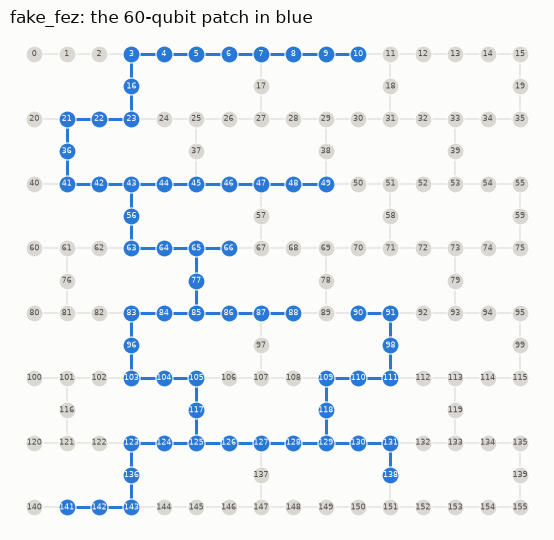

In [2]:
N = 60
phys, edges = patch(backend, N)
print(f"{N} qubits, {len(edges)} couplers, {len(edge_layers(N, edges))} layers of disjoint gates")
fig = report.fig_lattice(backend, highlight=phys, title=f"{backend.name}: the {N}-qubit patch in blue")
plt.show()

## 2.2 The feature map

A feature map is a short list of gates. The Qiskit circuit and the classical simulation are both built from that list.

The default map `zz` repeats this block:

- H on every qubit,
- RZ(x_q) on every qubit,
- RZZ(x_i x_j) on every coupler of the patch.

Here x_q is the rotation angle of gene q: the bandwidth times its clipped z-score. Four qubits in a line, one repetition:

In [3]:
small_ops = zz_map(4, [(0, 1), (1, 2), (2, 3)], reps=1)
small_qc, _ = to_circuit(4, small_ops)
print(small_qc.draw("text", fold=120))

     ┌───┐┌──────────┐                                
q_0: ┤ H ├┤ Rz(x[0]) ├─■──────────────────────────────
     ├───┤├──────────┤ │ZZ(x[0]*x[1])                 
q_1: ┤ H ├┤ Rz(x[1]) ├─■───────────────■──────────────
     ├───┤├──────────┤                 │ZZ(x[1]*x[2]) 
q_2: ┤ H ├┤ Rz(x[2]) ├─■───────────────■──────────────
     ├───┤├──────────┤ │ZZ(x[2]*x[3])                 
q_3: ┤ H ├┤ Rz(x[3]) ├─■──────────────────────────────
     └───┘└──────────┘                                


To add a map from the NAS, write a function with the same signature as `zz_map` in `pqk100/featuremap.py`
that returns the gate list, and register it in `FEATURE_MAPS`. Available now:

In [4]:
print(list(FEATURE_MAPS))

['zz', 'ry_cz']


## 2.3 Light cones

The expectation value of a Pauli on qubit k depends only on the gates in the backward light cone of k.
The RZZ gates of one repetition commute, so the cone grows by one lattice step per repetition.
On a heavy-hex lattice that is slow.

In [5]:
cones = report.cone_table(backend, n=156, reps=(1, 2, 3, 4, 5, 6))
cones

,largest cone (qubits),mean cone (qubits),CZ gates in largest cone,CZ gates in circuit,CZ depth
reps,,,,,
1,4,3.3,6,352,6
2,7,6.4,18,704,12
3,13,10.3,42,1056,18
4,19,15.8,78,1408,24
5,31,22.7,138,1760,30
6,41,30.7,222,2112,36


Up to 4 repetitions every single-qubit reduced density matrix of the 156-qubit circuit is a statevector calculation on at most 19 qubits.
`projections` does that for all qubits and all samples at once and returns an array of shape (samples, 3, qubits) holding ⟨X⟩, ⟨Y⟩, ⟨Z⟩.

## 2.4 Check 1: against Qiskit on a full circuit

16 qubits, full statevector, compared with the light-cone values.

In [6]:
def qiskit_reference(n, ops, X):
    qc, x = to_circuit(n, ops)
    ref = np.zeros((len(X), 3, n))
    for s, row in enumerate(X):
        sv = Statevector(qc.assign_parameters({x: row}))
        for a, P in enumerate("XYZ"):
            for k in range(n):
                ref[s, a, k] = sv.expectation_value(SparsePauliOp.from_sparse_list([(P, [k], 1.0)], n)).real
    return ref

rng = np.random.default_rng(1)
n = 16
_, e16 = patch(backend, n)
X = rng.normal(size=(3, n))
rows = []
for name, fm in FEATURE_MAPS.items():
    for reps in (1, 2, 3):
        ops = fm(n, e16, reps=reps)
        got, sizes = projections(n, ops, X)
        rows.append({"map": name, "reps": reps, "largest cone": int(sizes.max()),
                     "max |light cone - Qiskit|": np.abs(got - qiskit_reference(n, ops, X)).max()})
pd.DataFrame(rows)

,map,reps,largest cone,max |light cone - Qiskit|
0,zz,1,3,1.797451e-13
1,zz,2,5,1.265654e-14
2,zz,3,7,1.065814e-14
3,ry_cz,1,3,1.632028e-14
4,ry_cz,2,5,9.325873e-15
5,ry_cz,3,7,1.043610e-14


## 2.5 Check 2: matrix product state on the whole 156-qubit circuit

A second classical method that does not use light cones. The error falls as the bond dimension grows.
This is also the fallback when cones get too large for exact simulation.
Bond dimension 32 takes roughly 15 seconds per sample.

In [7]:
from qiskit_aer import AerSimulator

def mps_projections(n, ops, angles_row, chi):
    qc, x = to_circuit(n, ops)
    c = qc.assign_parameters({x: angles_row})
    for P in "XYZ":
        for k in range(n):
            c.save_expectation_value(SparsePauliOp.from_sparse_list([(P, [k], 1.0)], n), list(range(n)), label=f"{P}{k}")
    sim = AerSimulator(method="matrix_product_state", matrix_product_state_max_bond_dimension=chi)
    d = sim.run(c).result().data()
    return np.array([[d[f"{P}{k}"] for k in range(n)] for P in "XYZ"])

n = 156
_, e156 = patch(backend, n)
ops = zz_map(n, e156, reps=2)
row = np.clip(np.random.default_rng(0).normal(size=n), -3, 3) * 0.5
exact, _ = projections(n, ops, row[None, :])
rows = []
for chi in (8, 32):
    t = time.time(); got = mps_projections(n, ops, row, chi)
    rows.append({"bond dimension": chi, "max |MPS - exact|": np.abs(got - exact[0]).max(), "seconds": round(time.time() - t, 1)})
pd.DataFrame(rows)

,bond dimension,max |MPS - exact|,seconds
0,8,0.030989,0.5
1,32,0.000450,16.9


## 2.6 One experiment at 156 qubits

Same data split, gene panel, and scoring as the hardware notebook, with exact projections.
The projected quantum kernel is an RBF kernel on the 3 x 156 measured values, so it is tuned on the same grid as the classical RBF-SVM.

In [8]:
import pqk100.baselines as B
from pqk100.data import load_cohorts
from pqk100.prep import make_split, select_genes, to_angles
from pqk100.kernel import features, fit_pqk, concentration

SEED, N, REPS, BANDWIDTH = 0, 156, 2, 0.25
tcga, meta = load_cohorts()
sp = make_split(tcga, meta, "TP53", n_train=200, n_test=200, n_ext=400, seed=SEED, scaling="cohort")
genes = select_genes(sp.Xtr, sp.ytr, N)                      # chosen on the training tumors only
Z = np.vstack([sp.Xtr[:, genes], sp.Xte[:, genes], sp.Xex[:, genes]])
ntr, nte = len(sp.ytr), len(sp.yte)
print("first genes in the panel:", ", ".join(sp.genes[genes[:8]]))

_, edges = patch(backend, N)
ops = zz_map(N, edges, reps=REPS)
t = time.time()
P, sizes = projections(N, ops, to_angles(Z, BANDWIDTH))
print(f"{P.shape[0]} samples x 3 Paulis x {P.shape[2]} qubits in {time.time() - t:.1f} s (largest cone {sizes.max()} qubits)")

first genes in the panel: TBC1D9, A2ML1, ARSG, MYBL2, KCNJ11, LONRF2, MAPT, NOSTRIN
800 samples x 3 Paulis x 156 qubits in 1.3 s (largest cone 7 qubits)


In [9]:
F = features(P)
split = lambda M: {"in": (M[ntr:ntr + nte], sp.yte), "ext": (M[ntr + nte:], sp.yex)}
res = {"PQK (exact)": B.evaluate(fit_pqk, F[:ntr], sp.ytr, split(F), SEED),
       "RBF-SVM": B.evaluate(B.fit_rbf_svm, Z[:ntr], sp.ytr, split(Z), SEED),
       "Logistic regression": B.evaluate(B.fit_logreg, Z[:ntr], sp.ytr, split(Z), SEED),
       "Gradient boosting": B.evaluate(B.fit_gbm, Z[:ntr], sp.ytr, split(Z), SEED)}
pd.DataFrame({k: {"CV AUC (train)": r["cv_auc"], "AUC held-out TCGA": r["in_auc"], "AUC METABRIC": r["ext_auc"]}
              for k, r in res.items()}).T.round(3)

,CV AUC (train),AUC held-out TCGA,AUC METABRIC
PQK (exact),0.953,0.899,0.853
RBF-SVM,0.951,0.902,0.852
Logistic regression,0.943,0.913,0.858
Gradient boosting,0.912,0.926,0.828


Concentration measures for this circuit, on the training samples:

- `bloch_norm`: mean length of the single-qubit Bloch vectors. 1 is a product state, 0 is a fully mixed marginal.
- `feature_spread`: mean standard deviation of each expectation value across samples. Shot noise has to sit well below it.
- `d2_cv`: relative spread of pairwise squared distances between samples.

In [10]:
pd.Series(concentration(P[:ntr])).round(4)

bloch_norm        0.9942
feature_spread    0.1122
d2_cv             0.6250
k_offdiag_var     0.0071
dtype: float64

## 2.7 The control that matters: remove the entangling gates

`strip_entanglers` deletes every two-qubit gate. What is left is a product state, classical by construction.
If the stripped circuit scores the same, the result does not come from entanglement.

In [11]:
F0 = features(projections(N, strip_entanglers(ops), to_angles(Z, BANDWIDTH))[0])
F0 = F0[:, F0.std(0) > 1e-12]
r0 = B.evaluate(fit_pqk, F0[:ntr], sp.ytr, split(F0), SEED)
pd.DataFrame({"PQK": res["PQK (exact)"], "PQK, entanglers removed": r0}).loc[["cv_auc", "in_auc", "ext_auc"]].astype(float).round(3)

,PQK,"PQK, entanglers removed"
cv_auc,0.953,0.953
in_auc,0.899,0.907
ext_auc,0.853,0.865
